In [1]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.grummon2023 as _grummon2023_mod
import data.grummon2025 as _grummon2025_mod
from data.grummon2025 import ARM_NAMES, PRIMARY_CHOICE_STEMS
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _grummon2023_mod,
    _grummon2025_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_persona_dataset
from data.grummon2023 import load_grummon2023_df
from data.grummon2025 import load_grummon2025
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from training import MarginalGroupedTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")

Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load Grummon 2023 (train) and Grummon 2025 (eval)

In [2]:
INCLUDE_COUNTRY = False

train_df = load_grummon2023_df()

print(
    f"Grummon 2023: {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions | "
    f"{train_df['CASEID'].nunique():,} respondents"
)

Grummon 2023:    254,145 rows |  160 questions | 7,945 respondents


### build datasets

In [3]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_grummon2023"
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

GRUMMON2025_QIDS = [f"grummon2025:{arm}:{v}" for arm in ARM_NAMES for v in PRIMARY_CHOICE_STEMS]
grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False, qids=GRUMMON2025_QIDS)
# grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [grummon2025_grouped]

print(
    f"Train records : {len(train_records):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval set      : grummon2025={len(grummon2025_grouped['records']):,} "
    f"({len(grummon2025_grouped['packed_views']):,} states)"
)

Loaded 254,145 records from train_records_grummon2023_minNone_d36b8c7a.pkl
Train records : 254,145 (160 questions | 7,813 unique personas, 67 trait-value masks)
Eval set      : grummon2025=33,798 (4,727 states)


In [4]:
train_rec_qids = set(train_df["qid"].unique())
grummon2025_rec_qids = {r["qid"] for r in grummon2025_grouped["records"]}
train_rec_texts = set(train_df["question"].str.strip().unique())
grummon2025_rec_texts = {r["question"].strip() for r in grummon2025_grouped["records"]}

assert train_rec_qids.isdisjoint(grummon2025_rec_qids), f"Train/Grummon 2025 QID overlap: {train_rec_qids & grummon2025_rec_qids}"
assert train_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between train and grummon2025!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, grummon2025={len(grummon2025_rec_qids):,}\n"
    f"Question overlaps: train∩grummon2025={len(train_rec_texts & grummon2025_rec_texts)}"
)

QID counts       : train=160, grummon2025=36
Question overlaps: train∩grummon2025=0


## 2. Configure & Instantiate Trainer

In [10]:
resume = False
val_every = 100  
save_every = None
epochs = 2
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")

trainer_cfg = dict(
    base_model="jaredpalmer/kev-0.8b",
    save_dir="runs/test-kev-0.8b-resp-grummon2023-marginals",
    weights_dtype="bf16",
    use_bf16=True,
    gradient_checkpointing=False,
    max_questions_per_group=32,
    max_chars_per_group=20_000,
    eval_bf16=True,
    eval_max_questions=1024,
    eval_max_chars=360_000,
)

trainer = None
free_gpu()

trainer = MarginalGroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,MarginalGroupedTrainer
k_schedule,"(1, 2, 3, 4, 5, full, full)"
unique_personas,7813
trait_value_masks,67
run_name,test-kev-0.8b-resp-grummon2023-marginals
save_dir,runs/test-kev-0.8b-resp-grummon2023-marginals
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64


### Check epoch groups

In [16]:
sample_epoch = trainer._epoch_groups_for(0)

In [17]:
len(sample_epoch)

15770

In [23]:
sample_group_1 = sample_epoch[0]
sample_group_2 = sample_epoch[1]
len(sample_group_1), sample_group_1[0]

(30,
 {'qid': 'grummon2023:TrafficLight:infl_snack',
  'year': 'grummon2023',
  'v': 'infl_snack',
  'type': 'choice',
  'question': 'Labels shown: [CHOOSE OFTEN (green label, smiling face)], [CHOOSE SOMETIMES (yellow label, neutral face)], and [CHOOSE RARELY (red label, frowning face)].\n\nDid the labels influence which snack you selected?',
  'option_texts': ['Yes', 'No', 'Did not see the label'],
  'option_descriptions': None,
  'personas': {'EDULEVEL': 'Less than high school',
   'NFPUSE': 'Sometimes',
   'MEDHELP': 'Sometimes',
   'VENDING_BEV': 'Never or less than 1 time per week'},
  'attribute': 'EDULEVEL+NFPUSE+MEDHELP+VENDING_BEV',
  'persona': 'Education=Less than high school, Nutrition Facts label usage=Sometimes, How often do you need to have someone help you when you read instructions, pamphlets, or other written materials from your doctor or pharmacy?=Sometimes, In a typical week, how often do you buy beverages from vending machines?=Never or less than 1 time per week',


In [24]:
[s['n'] for s in sample_group_1]

[5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5,
 5]

In [25]:
[s['n'] for s in sample_group_2]

[1, 1]

In [26]:
sample_group_2

[{'qid': 'grummon2023:PhysicalActivity:bev_choice',
  'year': 'grummon2023',
  'v': 'bev_choice',
  'type': 'choice',
  'question': 'In this survey, you will see beverages and snacks you might see in a vending machine. We will ask you to select the beverage and the snack you would most like to purchase. We will randomly select 100 respondents to receive a "bonus" for completing this part of the survey. If you are selected for the bonus, you will have one of your product selections delivered to you.\nYou should choose the beverage and snack you most want to purchase because your choices could be delivered to you.\n\nThe next section is about beverage choices. You will see beverages you might see in a vending machine. We will ask you to select the beverage you would most like to purchase.\nIf you see a beverage brand you want but don\'t see the flavor you want, please still select that beverage regardless of the flavor available.\n\nPoster shown — DID YOU KNOW IT TAKES 115 MINS OF BRISK 

## 3. Train one epoch

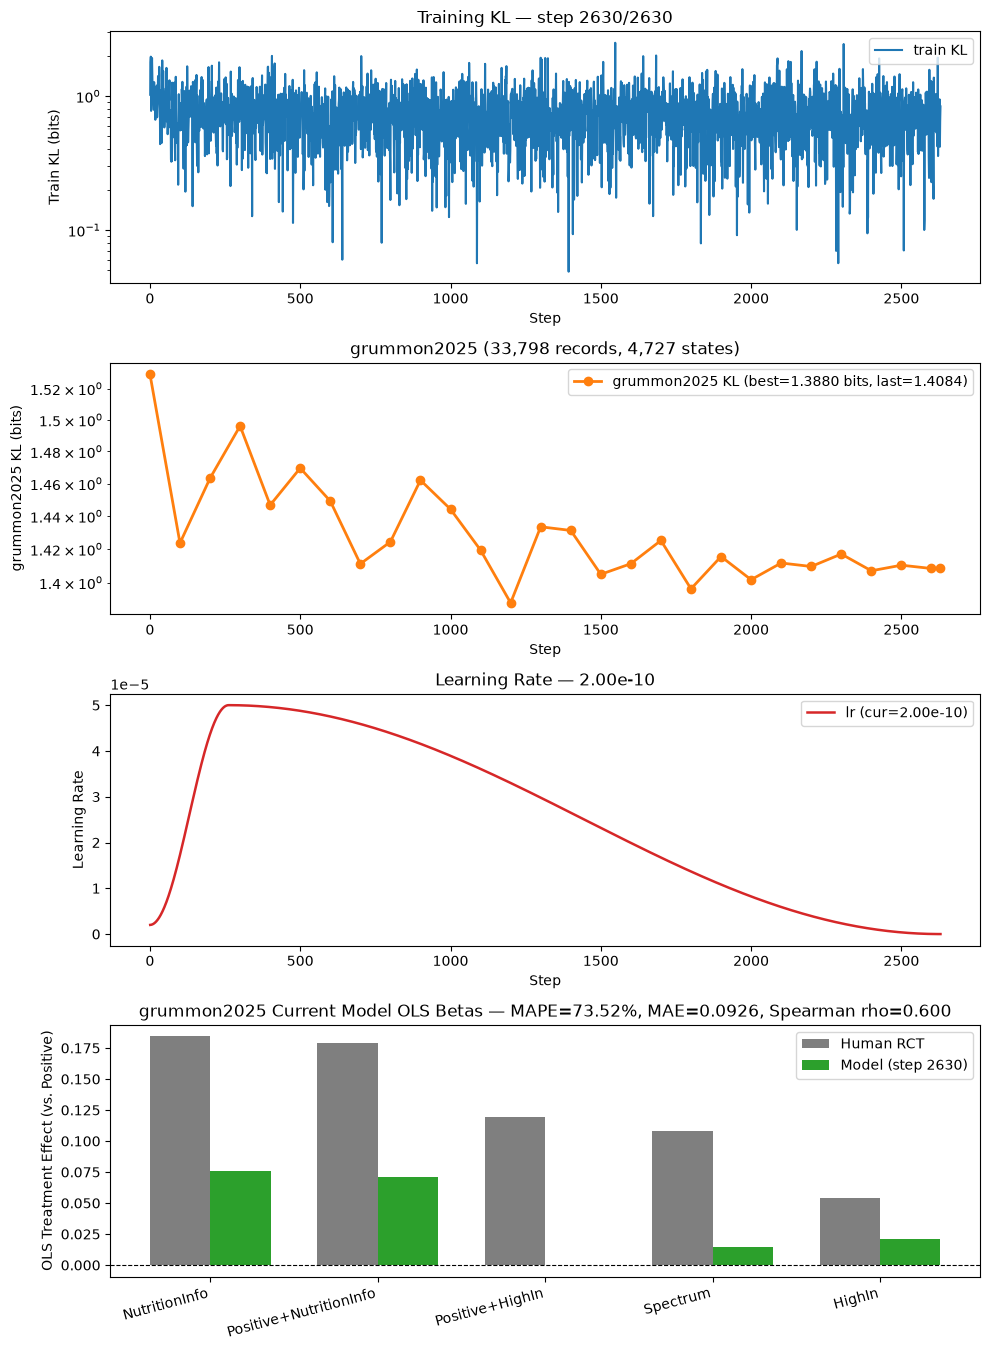

,epoch,step,train_kl,grummon2025_kl,grummon2025_OLS MAPE (%),grummon2025_OLS MAE,grummon2025_OLS MSE,grummon2025_Spearman rho
0,0,0,—,1.5294,63.87,0.0650,0.0054,0.5000
1,1,100,0.8181,1.4236,72.52,0.1029,0.0135,-0.3000
2,1,200,0.8367,1.4633,87.94,0.1182,0.0167,-0.7000
3,1,300,0.9699,1.4961,78.60,0.1059,0.0134,0.5000
4,1,400,0.3393,1.4467,90.39,0.1137,0.0143,0.7000
5,1,500,0.8127,1.4696,54.30,0.0787,0.0080,0.6000
6,1,600,0.2274,1.4492,66.89,0.0913,0.0100,0.6000
7,1,700,0.8893,1.4111,64.45,0.0856,0.0086,0.7000
8,1,800,0.1679,1.4244,80.50,0.1042,0.0122,0.6000
9,1,900,1.1943,1.4621,73.48,0.0962,0.0106,0.7000


,human,model,abs_diff
NutritionInfo,0.1844,0.0761,0.1084
Positive+NutritionInfo,0.1788,0.0709,0.1079
Positive+HighIn,0.1194,-0.0002,0.1196
Spectrum,0.1083,0.0144,0.0939
HighIn,0.0541,0.0207,0.0334


In [11]:
plotter = trainer.train()

## 4. Grummon 2025 results (step 0 vs final)

In [12]:
display(pd.DataFrame(plotter.val_rows))
display(plotter.latest_ols_df["grummon2025"])

,epoch,step,train_kl,grummon2025_kl,grummon2025_OLS MAPE (%),grummon2025_OLS MAE,grummon2025_OLS MSE,grummon2025_Spearman rho
0,0,0,NaN,1.529425,63.873737,0.065016,0.005421,0.5
1,1,100,0.818050,1.423629,72.522182,0.102882,0.013459,-0.3
2,1,200,0.836667,1.463293,87.941523,0.118171,0.016663,-0.7
3,1,300,0.969887,1.496089,78.597124,0.105904,0.013387,0.5
4,1,400,0.339326,1.446732,90.393593,0.113736,0.014278,0.7
5,1,500,0.812727,1.469593,54.303228,0.078680,0.008028,0.6
6,1,600,0.227416,1.449208,66.891275,0.091334,0.010035,0.6
7,1,700,0.889285,1.411128,64.451903,0.085634,0.008590,0.7
8,1,800,0.167907,1.424354,80.504279,0.104170,0.012226,0.6
9,1,900,1.194259,1.462075,73.478895,0.096190,0.010632,0.7


,human,model,abs_diff
NutritionInfo,0.184416,0.076052,0.108363
Positive+NutritionInfo,0.178838,0.070933,0.107905
Positive+HighIn,0.119443,-0.000150,0.119594
Spectrum,0.108316,0.014380,0.093936
HighIn,0.054095,0.020737,0.033358


## Compare old runs against this

In [13]:
import torch
from data.base import evaluate_model
from models.kev_pointer import KevPointerModel
from training.trainer import load_checkpoint

COMPARE_CKPTS = {
    "base (untrained)": "jaredpalmer/kev-0.8b",
    "grummon2023-marginals (this run)": "runs/test-kev-0.8b-resp-grummon2023-marginals/last",
    "issp+twin2k-diversevalid-marginals": "runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals/best",
    "issp+twin2k-diversevalid-marginals-ep2": "runs/kev-0.8b-resp-issp+twin2k-diversevalid-marginals-ep2/best",
    "issp+twin2k+wvs-diversevalid-marginals": "runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals/best",
    "issp+twin2k+wvs-diversevalid-marginals-2epochs": "runs/kev-0.8b-resp-issp+twin2k+wvs-diversevalid-marginals-2epochs/best",
    "issp+twin2k-grouped-diversevalid-grouped": "runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-grouped/best",
    "issp+twin2k-grouped-diversevalid-iid": "runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid/best",
    "issp+twin2k-grouped-diversevalid-iid-2epochs": "runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid-2epochs/best",
    "issp+twin2k-grouped-diversevalid-iid-ep2": "runs/kev-0.8b-resp-issp+twin2k-grouped-diversevalid-iid-ep2/best",
    "issp+twin2k-grouped-newvalid": "runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid/best",
    "issp+twin2k-grouped": "runs/kev-0.8b-resp-issp+twin2k-grouped/best",
    "issp+twin2k-bs64": "runs/kev-0.8b-resp-issp+twin2k-bs64/best",
}

trainer = None
free_gpu()

compare_summaries = {}
compare_betas = {}
for name, ckpt in COMPARE_CKPTS.items():
    if ckpt.startswith("runs/"):
        model = load_checkpoint(ckpt, trainable=True, lora_rank=None, weights_dtype="bf16")
    else:
        model = KevPointerModel.build(ckpt, "cuda", lora_rank=None, weights_dtype="bf16")
        model.net.head.temperature = 1.0
    with torch.autocast("cuda", dtype=torch.bfloat16):
        summary, _ = evaluate_model(
            model, grummon2025_grouped, max_questions=1024, max_chars=360_000, show_progress=True
        )
    compare_summaries[name] = summary
    compare_betas[name] = grummon2025_grouped["last_extra_df"]["model"].copy()
    human_betas = grummon2025_grouped["last_extra_df"]["human"].copy()
    del model
    free_gpu()
    print(f"{name}: kl={summary['dist_kl']:.4f} | OLS MAE={summary['OLS MAE']:.4f}")

display(pd.DataFrame(compare_summaries).T.round(4))
display(pd.concat({"human": human_betas, **compare_betas}, axis=1).round(4))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Evaluating grummon2025 (shared-state):   0%|          | 0/89 [00:00<?, ?batch/s]

base (untrained): kl=1.5294 | OLS MAE=0.0650


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

... (33 outputs left out)

Evaluating grummon2025 (shared-state):   0%|          | 0/89 [00:00<?, ?batch/s]

issp+twin2k-bs64: kl=1.5049 | OLS MAE=0.0635


,ce,dist_kl,OLS MAPE (%),OLS MSE,OLS MAE,Spearman rho
base (untrained),1.5294,1.5294,63.8737,0.0054,0.0650,0.5
grummon2023-marginals (this run),1.4084,1.4084,73.5226,0.0095,0.0926,0.6
issp+twin2k-diversevalid-marginals,1.5788,1.5788,58.9670,0.0070,0.0705,0.7
issp+twin2k-diversevalid-marginals-ep2,1.5447,1.5447,57.8876,0.0065,0.0687,0.7
issp+twin2k+wvs-diversevalid-marginals,1.6153,1.6153,61.6899,0.0076,0.0786,0.7
issp+twin2k+wvs-diversevalid-marginals-2epochs,1.5720,1.5720,64.5029,0.0080,0.0804,0.7
issp+twin2k-grouped-diversevalid-grouped,1.6180,1.6180,55.5808,0.0067,0.0732,0.7
issp+twin2k-grouped-diversevalid-iid,1.6432,1.6432,81.6441,0.0109,0.0992,0.7
issp+twin2k-grouped-diversevalid-iid-2epochs,1.6089,1.6089,83.5240,0.0107,0.0982,0.7
issp+twin2k-grouped-diversevalid-iid-ep2,1.6518,1.6518,81.0150,0.0113,0.1005,0.7


,human,base (untrained),grummon2023-marginals (this run),issp+twin2k-diversevalid-marginals,issp+twin2k-diversevalid-marginals-ep2,issp+twin2k+wvs-diversevalid-marginals,issp+twin2k+wvs-diversevalid-marginals-2epochs,issp+twin2k-grouped-diversevalid-grouped,issp+twin2k-grouped-diversevalid-iid,issp+twin2k-grouped-diversevalid-iid-2epochs,issp+twin2k-grouped-diversevalid-iid-ep2,issp+twin2k-grouped-newvalid,issp+twin2k-grouped,issp+twin2k-bs64
NutritionInfo,0.1844,0.1256,0.0761,0.1217,0.1276,0.1073,0.1001,0.1038,0.0658,0.0767,0.0626,0.1175,0.1229,0.1073
Positive+NutritionInfo,0.1788,0.1552,0.0709,0.1094,0.1109,0.0804,0.0812,0.0873,0.0517,0.0578,0.0487,0.1075,0.1096,0.0913
Positive+HighIn,0.1194,-0.0084,-0.0002,-0.0350,-0.0298,-0.0150,-0.0218,-0.0064,-0.0118,-0.0202,-0.0119,-0.0357,0.0002,0.0059
Spectrum,0.1083,0.0597,0.0144,0.0772,0.0734,0.0493,0.0629,0.0567,0.0463,0.0523,0.0395,0.0592,0.0830,0.0900
HighIn,0.0541,0.1203,0.0207,0.0195,0.0198,0.0300,0.0206,0.0379,-0.0031,-0.0124,0.0039,0.0156,0.0453,0.0749
